## 1. Setup

In [1]:
from pathlib import Path
import sys
import json
import os

# Make the local package importable regardless of where the kernel starts.
ROOT = Path.cwd()
if not (ROOT / "src" / "smcii").exists():
    # fall back to the directory that contains this notebook
    ROOT = Path(globals().get("__file__", ROOT)).resolve().parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from smcii import config

FIG_DIR = config.ARTIFACTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60)

print("project root :", config.PROJECT_ROOT)
print("raw dataset  :", config.RAW_DATASET)
print("target       :", config.TARGET)
print("figures dir  :", FIG_DIR)


def show(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

project root : /home/sayan/Desktop/AI Essentials/Project
raw dataset  : /home/sayan/Desktop/AI Essentials/Project/data/social_media_impact.csv
target       : Mental_Health_Index
figures dir  : /home/sayan/Desktop/AI Essentials/Project/artifacts/figures


## 2. Data

In [2]:
raw = pd.read_csv(config.RAW_DATASET)
print("raw shape:", raw.shape)
print()
print("dtypes:")
display(raw.dtypes.to_frame("dtype"))
print("null counts (non-zero):")
nulls = raw.isnull().sum()
display(nulls[nulls > 0].to_frame("n_null"))
print("describe():")
display(raw.describe(include="all").T)

raw shape: (4500, 16)

dtypes:


,dtype
Student_ID,str
Age,int64
Gender,str
Academic_Level,str
Primary_Platform,str
Daily_Usage_Hours,float64
Weekend_Extra_Hours,float64
Device_Type,str
Sleep_Duration_Hours,float64
Sleep_Quality_Score,int64


null counts (non-zero):


,n_null
Perceived_Stress_Score,46
Academic_Performance_GPA,85


describe():


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,4500,4500,STU_2024000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,4500.0,NaN,NaN,NaN,18.703333,1.981182,15.0,17.0,19.0,20.0,26.0
Gender,4500,4,Female,2234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,4500,3,Undergraduate,2777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Primary_Platform,4500,7,Instagram,1453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Daily_Usage_Hours,4500.0,NaN,NaN,NaN,5.295933,2.604497,0.9,3.4,4.7,6.6,14.0
Weekend_Extra_Hours,4500.0,NaN,NaN,NaN,1.796844,0.699245,0.0,1.3,1.8,2.3,4.5
Device_Type,4500,3,Smartphone,3775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Duration_Hours,4500.0,NaN,NaN,NaN,6.701333,1.189998,3.0,6.0,6.8,7.5,10.5
Sleep_Quality_Score,4500.0,NaN,NaN,NaN,2.472,1.030484,1.0,2.0,3.0,3.0,5.0


### 2.1 Exploratory data analysis

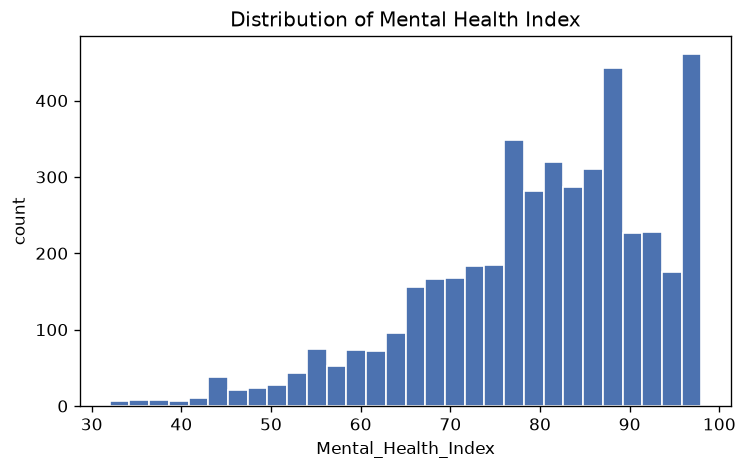

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(raw[config.TARGET].dropna(), bins=30, color="#4C72B0", edgecolor="white")
ax.set_title("Distribution of Mental Health Index")
ax.set_xlabel(config.TARGET)
ax.set_ylabel("count")
show(fig, "target_distribution.png")

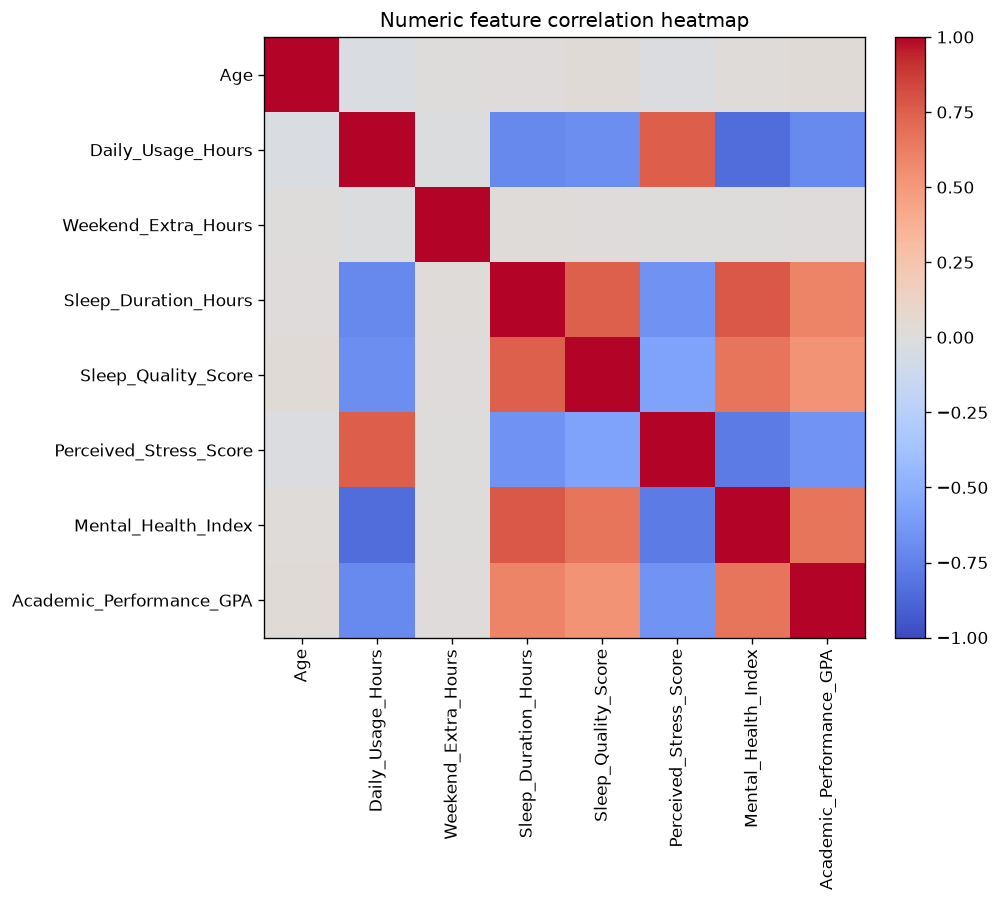

In [4]:
numeric = raw.select_dtypes(include=[np.number])
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
ax.set_title("Numeric feature correlation heatmap")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
show(fig, "correlation_heatmap.png")

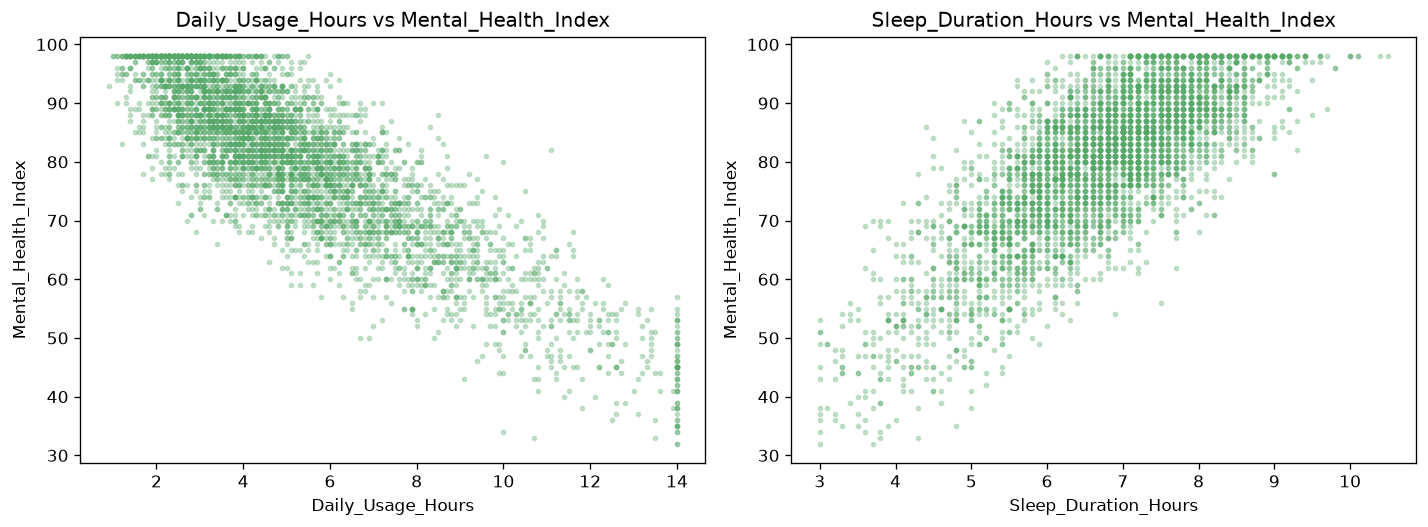

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feat in zip(axes, ["Daily_Usage_Hours", "Sleep_Duration_Hours"]):
    ax.scatter(raw[feat], raw[config.TARGET], s=6, alpha=0.3, color="#55A868")
    ax.set_xlabel(feat)
    ax.set_ylabel(config.TARGET)
    ax.set_title(f"{feat} vs {config.TARGET}")
fig.tight_layout()
show(fig, "actionable_vs_target.png")

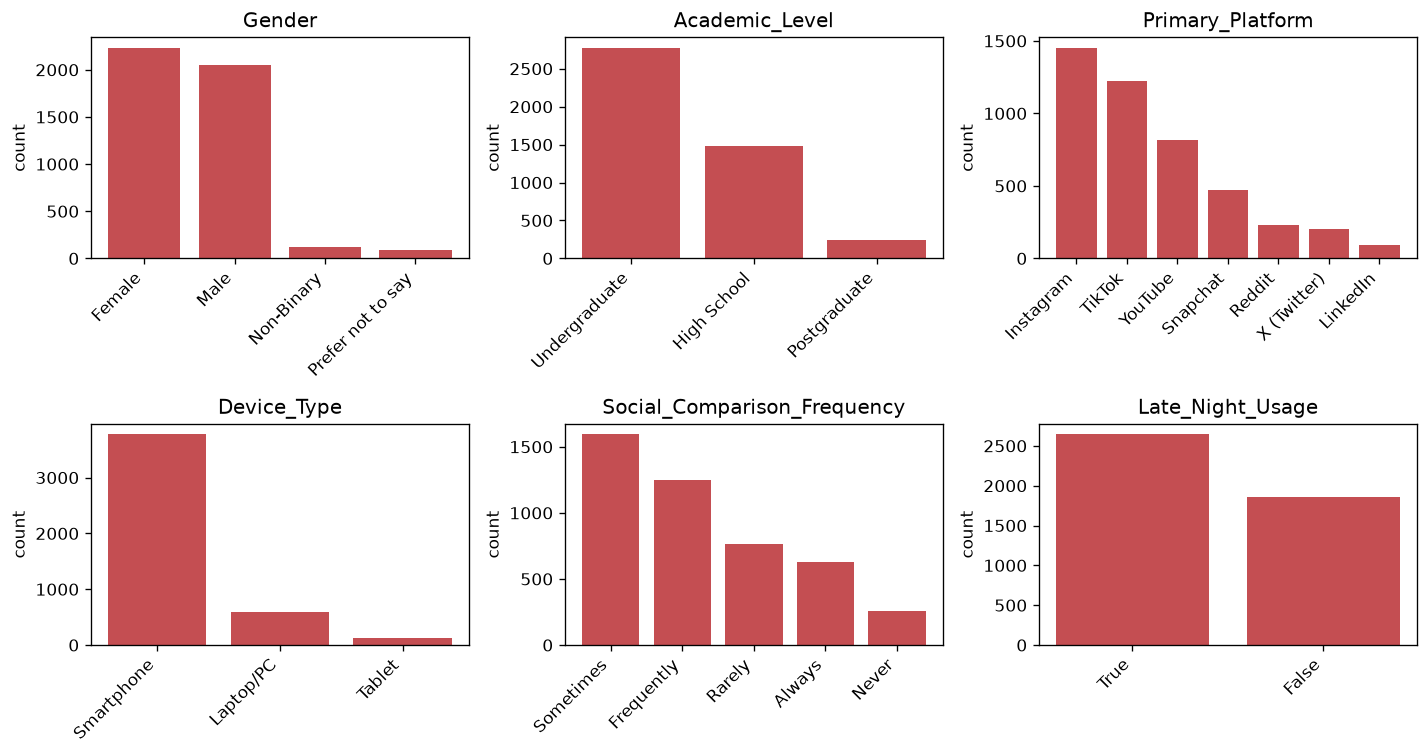

In [6]:
cat_cols = list(config.CATEGORICAL_FEATURES)
n_cols = 3
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, cat_cols):
    counts = raw[col].astype(str).value_counts()
    ax.bar(range(len(counts)), counts.values, color="#C44E52")
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha="right")
    ax.set_title(col)
    ax.set_ylabel("count")
for ax in axes[len(cat_cols):]:
    ax.axis("off")
fig.tight_layout()
show(fig, "categorical_counts.png")

## 3. Feature policy

In [7]:
rows = [{"role": "immutable", "feature": f} for f in config.IMMUTABLE_FEATURES]
rows += [{"role": "actionable", "feature": f} for f in config.ACTIONABLE_FEATURES]
display(pd.DataFrame(rows))

print("Permitted range for actionable continuous features:")
display(pd.DataFrame(
    {k: {"lo": v[0], "hi": v[1]} for k, v in config.PERMITTED_RANGE.items()}
).T)

,role,feature
0,immutable,Age
1,immutable,Gender
2,immutable,Academic_Level
3,immutable,Sleep_Quality_Score
4,immutable,Social_Comparison_Frequency
5,immutable,Perceived_Stress_Score
6,immutable,Late_Night_Usage
7,immutable,Weekend_Extra_Hours
8,immutable,Academic_Performance_GPA
9,actionable,Sleep_Duration_Hours


Permitted range for actionable continuous features:


,lo,hi
Sleep_Duration_Hours,4.0,10.0
Daily_Usage_Hours,0.0,8.0


## 4. Forward model — metrics

In [8]:
with open(config.METRICS_PATH) as f:
    metrics = json.load(f)

summary_rows = []
mlp = metrics.get("mlp", {})
lgbm = metrics.get("lightgbm", {})
summary_rows.append({"model": "MLP", "cv_mae": mlp.get("cv_mae"),
                     "holdout_mae": mlp.get("holdout_mae"), "rmse": mlp.get("rmse")})
summary_rows.append({"model": "LightGBM", "cv_mae": lgbm.get("cv_mae"),
                     "holdout_mae": lgbm.get("holdout_mae"), "rmse": lgbm.get("rmse")})
display(pd.DataFrame(summary_rows).round(4))
print("selected:", metrics.get("selected"), "| deployed:", metrics.get("deployed"))
print("n_train:", metrics.get("n_train"), "| n_test:", metrics.get("n_test"))

,model,cv_mae,holdout_mae,rmse
0,MLP,4.6725,4.5687,5.7526
1,LightGBM,NaN,4.9667,6.1272


selected: mlp | deployed: mlp
n_train: 3495 | n_test: 874


int8 ONNX holdout MAE: 4.5657


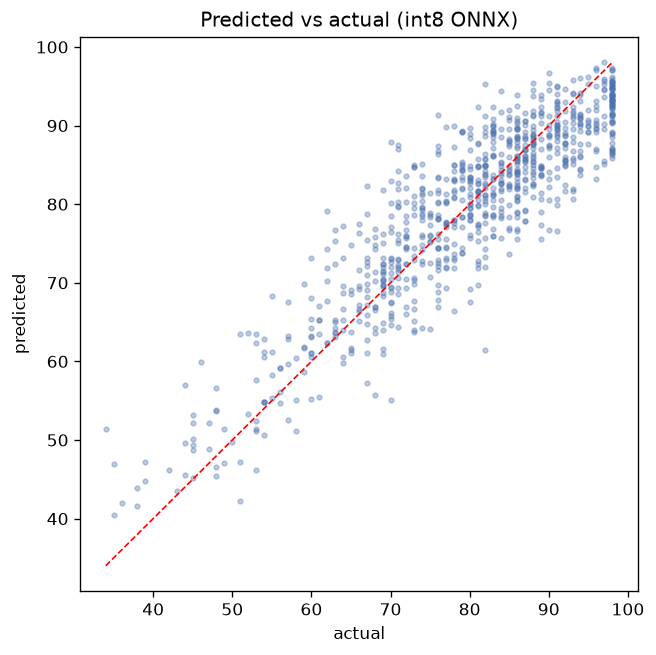

In [9]:
from smcii import data as smdata, preprocess

_, test_df = smdata.split()
X_test, y_test = smdata.X_y(test_df)
X_test_t = preprocess.transform(X_test).astype(np.float32)

try:
    import onnxruntime as ort
    sess = ort.InferenceSession(str(config.MODEL_ONNX_INT8_PATH),
                                providers=["CPUExecutionProvider"])
    y_pred = sess.run(None, {"input": X_test_t})[0].flatten()
    mae = float(np.mean(np.abs(y_pred - y_test.values)))
    print(f"int8 ONNX holdout MAE: {mae:.4f}")

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y_test.values, y_pred, s=8, alpha=0.35, color="#4C72B0")
    lo = min(float(y_test.min()), float(y_pred.min()))
    hi = max(float(y_test.max()), float(y_pred.max()))
    ax.plot([lo, hi], [lo, hi], "r--", lw=1)
    ax.set_xlabel("actual")
    ax.set_ylabel("predicted")
    ax.set_title("Predicted vs actual (int8 ONNX)")
    show(fig, "predicted_vs_actual.png")
except Exception as e:
    print("ONNX runtime unavailable:", repr(e))

## 5. Counterfactual demo

Pick a below-threshold test profile, then ask the engine for the smallest set of
actionable changes that push the prediction above the target threshold.

> This cell is guarded: if the counterfactual lane is still in progress, it
> prints a note instead of aborting the notebook.

In [10]:
def predict_profile(df):
    import onnxruntime as ort
    X = preprocess.transform(df[config.ALL_FEATURES]).astype(np.float32)
    sess = ort.InferenceSession(str(config.MODEL_ONNX_INT8_PATH),
                                providers=["CPUExecutionProvider"])
    return sess.run(None, {"input": X})[0].flatten()

below = test_df[test_df[config.TARGET] < config.DEFAULT_TARGET_THRESHOLD]
if len(below) == 0:
    print("No below-threshold profiles found in the test set.")
else:
    profile = below[config.ALL_FEATURES].iloc[0].to_dict()
    current = float(predict_profile(pd.DataFrame([profile]))[0])
    print(f"Target threshold: {config.DEFAULT_TARGET_THRESHOLD}")
    print(f"Current prediction: {current:.2f}")
    print("Current actionable profile:")
    display(pd.DataFrame([{k: profile[k] for k in config.ACTIONABLE_FEATURES}]))

    try:
        from smcii import counterfactual
        cfs = counterfactual.suggest(profile, target=config.DEFAULT_TARGET_THRESHOLD)
        if cfs:
            rows = []
            for i, cf in enumerate(cfs):
                rows.append({
                    "#": i,
                    "prediction": round(float(cf.get("prediction", float("nan"))), 2),
                    "num_changes": cf.get("num_changes"),
                    "changes": cf.get("changes"),
                    "met_target": cf.get("met_target"),
                })
            display(pd.DataFrame(rows))
        else:
            print("No counterfactuals returned.")
    except Exception as e:
        print("Counterfactual lane not ready — run this notebook after the app lane completes.")
        print("detail:", repr(e))

Target threshold: 75.0
Current prediction: 66.45
Current actionable profile:


,Sleep_Duration_Hours,Daily_Usage_Hours,Primary_Platform,Device_Type
0,5.5,8.0,TikTok,Smartphone


100%|██████████| 1/1 [00:00<00:00,  7.41it/s]


,#,prediction,num_changes,changes,met_target
0,0,78.05,1,"{'Sleep_Duration_Hours': [5.5, 9.6]}",True
1,1,75.49,2,"{'Sleep_Duration_Hours': [5.5, 9.2], 'Device_T...",True
2,2,79.40,2,"{'Daily_Usage_Hours': [8.0, 2.6], 'Primary_Pla...",True


## 6. Deployment & benchmarking

In [11]:
int8_mb = os.path.getsize(config.MODEL_ONNX_INT8_PATH) / (1024 * 1024)
fp32_mb = os.path.getsize(config.MODEL_ONNX_FP32_PATH) / (1024 * 1024)
print(f"fp32 ONNX payload: {fp32_mb:.4f} MB")
print(f"int8 ONNX payload: {int8_mb:.4f} MB (budget {config.MODEL_SIZE_BUDGET_MB} MB)")

fp32 ONNX payload: 0.0167 MB
int8 ONNX payload: 0.0079 MB (budget 5.0 MB)


In [12]:
result = None
try:
    from smcii import benchmark
    result = benchmark.run()
except Exception as e:
    print("Benchmark lane not ready yet:", repr(e))

if result is None and config.BENCHMARK_REPORT_PATH.exists():
    with open(config.BENCHMARK_REPORT_PATH) as f:
        result = json.load(f)

if result is not None:
    display(pd.DataFrame([result]) if isinstance(result, dict) else result)
else:
    print(f"Run the app lane to generate {config.BENCHMARK_REPORT_PATH}")

100%|██████████| 1/1 [00:00<00:00,  8.96it/s]

=== smcii benchmark ===
latency  p50=139.55ms  p95=152.91ms  p99=157.94ms  mean=139.65ms
memory   peak=291.9MB  current=289.5MB
payload  int8=0.0079MB  preprocessor=4.3KB
pass     latency_p95=True  memory_peak=True  model_size=True
report -> /home/sayan/Desktop/AI Essentials/Project/artifacts/benchmark_report.json


,latency_ms,memory_mb,payload,budgets,pass
0,"{'p50_ms': 139.55159249599092, 'p95_ms': 152.9...","{'peak_rss_mb': 291.8984375, 'current_rss_mb':...","{'onnx_int8_mb': 0.007886886596679688, 'prepro...","{'latency_budget_ms': 200.0, 'memory_budget_mb...","{'latency_p95': True, 'memory_peak': True, 'mo..."
